In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ضبط إعدادات العرض للرسوم البيانية
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# إنشاء بيانات مبيعات افتراضية منظمة (تجارية) لاختبار الكود
data = {
    'Order_ID': [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010],
    'Product': ['Laptop', 'Mouse', 'Keyboard', 'Monitor', 'Laptop', 'Mouse', 'Headphones', 'Monitor', 'Keyboard', 'Headphones'],
    'Category': ['Electronics', 'Accessories', 'Accessories', 'Electronics', 'Electronics', 'Accessories', 'Electronics', 'Electronics', 'Accessories', 'Electronics'],
    'Quantity': [2, 5, 3, 1, 1, 10, 4, 2, 6, 3],
    'Unit_Price': [800.0, 25.0, 45.0, 200.0, 800.0, 25.0, 60.0, 200.0, 45.0, 60.0],
    'Order_Date': ['2026-01-15', '2026-01-16', '2026-01-18', '2026-02-01', '2026-02-05', '2026-02-10', '2026-03-01', '2026-03-05', '2026-03-12', '2026-03-15'],
    'Customer_City': ['Cairo', 'Alexandria', 'Giza', 'Cairo', 'Mansoura', 'Alexandria', 'Cairo', 'Giza', 'Alexandria', 'Cairo']
}

df = pd.DataFrame(data)

# تحويل عمود التاريخ إلى DateTime
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# حساب إجمالي المبيعات (Total Sales)
df['Total_Sales'] = df['Quantity'] * df['Unit_Price']

# عرض أول 5 صفوف للتأكد من البيانات
print(df.head())

   Order_ID   Product     Category  Quantity  Unit_Price Order_Date  \
0      1001    Laptop  Electronics         2       800.0 2026-01-15   
1      1002     Mouse  Accessories         5        25.0 2026-01-16   
2      1003  Keyboard  Accessories         3        45.0 2026-01-18   
3      1004   Monitor  Electronics         1       200.0 2026-02-01   
4      1005    Laptop  Electronics         1       800.0 2026-02-05   

  Customer_City  Total_Sales  
0         Cairo       1600.0  
1    Alexandria        125.0  
2          Giza        135.0  
3         Cairo        200.0  
4      Mansoura        800.0  


In [2]:
# 1. إجمالي المبيعات الكلية للمتجر
total_revenue = df['Total_Sales'].sum()
print(f"Total Revenue (إجمالي المبيعات): ${total_revenue}\n")

# 2. أكثر المنتجات مبيعاً بناءً على إجمالي الإيرادات
top_products = df.groupby('Product')['Total_Sales'].sum().reset_index()
top_products = top_products.sort_values(by='Total_Sales', ascending=False)
print("Top Products by Sales:")
print(top_products, "\n")

# 3. المبيعات حسب المدن
city_sales = df.groupby('Customer_City')['Total_Sales'].sum().reset_index()
print("Sales by City:")
print(city_sales)

Total Revenue (إجمالي المبيعات): $4200.0

Top Products by Sales:
      Product  Total_Sales
2      Laptop       2400.0
3     Monitor        600.0
0  Headphones        420.0
1    Keyboard        405.0
4       Mouse        375.0 

Sales by City:
  Customer_City  Total_Sales
0    Alexandria        645.0
1         Cairo       2220.0
2          Giza        535.0
3      Mansoura        800.0


/tmp/ipykernel_994/992224251.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Total_Sales', y='Product', data=top_products, palette='Blues_r')
/tmp/ipykernel_994/992224251.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Customer_City', y='Total_Sales', data=city_sales, palette='Purples_r')


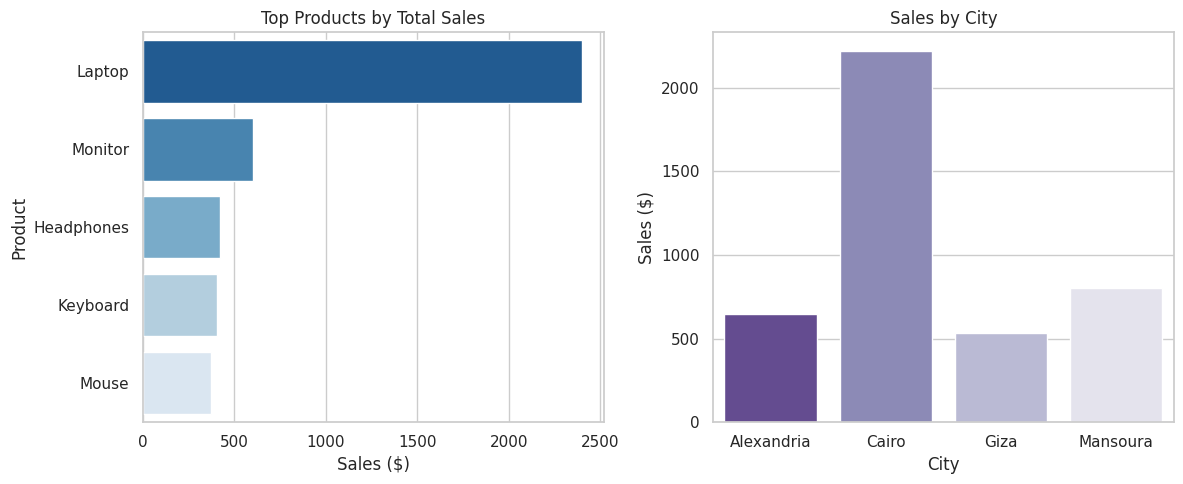

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# ضبط الأسلوب العام للرسوم البيانية
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))

# 1. رسم بياني لمبيعات المنتجات
plt.subplot(1, 2, 1)
sns.barplot(x='Total_Sales', y='Product', data=top_products, palette='Blues_r')
plt.title('Top Products by Total Sales')
plt.xlabel('Sales ($)')
plt.ylabel('Product')

# 2. رسم بياني لمبيعات المدن
plt.subplot(1, 2, 2)
sns.barplot(x='Customer_City', y='Total_Sales', data=city_sales, palette='Purples_r')
plt.title('Sales by City')
plt.xlabel('City')
plt.ylabel('Sales ($)')

plt.tight_layout()
plt.show()